# P1-02. PyTorch 기초 + 첫 모델 학습 (MLP)

**이 노트북의 목표**: 딥러닝 학습의 *전체 흐름*을 처음부터 끝까지 한 번 돌려보기.  
성능은 기대하지 않아요. 일부러 **가장 단순한 모델(MLP)**로 해서, 다음 노트북의 CNN과 비교할 기준점을 만들어요.

| sklearn에서는 | PyTorch에서는 | 이 노트북 섹션 |
|---|---|---|
| `X`, `y` 배열 | `Dataset` (한 장씩 꺼내주는 규칙) + `DataLoader` (배치로 묶어줌) | 3, 4 |
| `model = LogisticRegression()` | `nn.Module`로 모델 구조를 직접 정의 | 5 |
| `model.fit(X, y)` | **학습 루프를 직접 작성** (순전파 → 손실 → 역전파 → 가중치 갱신) | 6, 7 |
| `model.predict_proba(X)` | `model.eval()` + `torch.no_grad()` + `softmax` | 6, 9 |

> 위에서부터 순서대로 실행하세요. **8번(학습 곡선), 9번(test 성능), 10번(누수 실험) 출력**을 Claude에게 보내주세요.

## 0. 준비: 라이브러리, 시드, GPU 선택

In [3]:
import random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# 한글 폰트
_avail = {f.name for f in font_manager.fontManager.ttflist}
for _f in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if _f in _avail:
        plt.rcParams["font.family"] = _f; break
plt.rcParams["axes.unicode_minus"] = False

# 시드 고정: 같은 코드를 다시 돌려도 같은 결과가 나오게 (sklearn의 random_state와 같은 역할)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# GPU 선택: 0번 GPU 사용 (나중에 실험 2개를 동시에 돌릴 땐 다른 노트북에서 "cuda:1")
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("사용 장치:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

d:\yerimlee\medimg-study\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


사용 장치: cuda:0 | NVIDIA GeForce RTX 3080


## 1. Tensor 맛보기

PyTorch의 기본 자료형은 **Tensor**예요. numpy 배열과 거의 같은데, 두 가지가 더 돼요.
1. **GPU로 옮겨서 계산**할 수 있다 (`.to(DEVICE)`)
2. 계산 과정을 기억해서 **기울기(gradient)를 자동으로 계산**할 수 있다 → 역전파의 핵심

In [4]:
a = torch.tensor([[1., 2.], [3., 4.]]) # np array와 동일한 2*2 행렬
print("tensor:\n", a, "\nshape:", a.shape, "| dtype:", a.dtype, "| device:", a.device) # shape : 모양 (2,2), dtype: 숫자 종류 (float32, 소수점 숫자) 

b = a.to(DEVICE)                       # GPU로 이동
print("GPU로 옮긴 뒤 device:", b.device)

# 자동 미분: y = x^2 일 때 dy/dx = 2x → x=3이면 6
# 예시로 보여준거고 pytorch가 알아서함. 숫자까지 정해줄 필요는 X 
x = torch.tensor(3.0, requires_grad=True)
y = x ** 2
y.backward()                            # 역전파
print("x=3에서 y=x² 의 기울기:", x.grad.item())

tensor:
 tensor([[1., 2.],
        [3., 4.]]) 
shape: torch.Size([2, 2]) | dtype: torch.float32 | device: cpu
GPU로 옮긴 뒤 device: cuda:0
x=3에서 y=x² 의 기울기: 6.0


### 이미지 → Tensor 모양 확인

노트북 1에서 얘기한 것처럼 PIL/numpy는 `H × W × C`, PyTorch는 `C × H × W`(채널이 앞)예요.  
여러 장을 묶은 **배치**는 앞에 한 축이 더 붙어서 `N × C × H × W`가 돼요.
핵심: numpy와 torch는 축의 순서가 다름을 보여주기 위함
배치: 16장이 1개의 묶음으로 사용하며, 16장을 학습한 후 train loss를 보고 다음 배치에서의 가중치를 갱신함

In [5]:
from PIL import Image as _I
demo = np.zeros((512, 512, 3), dtype=np.uint8)            # 가짜 RGB 이미지 (H×W×C)
print("numpy (RGB) :", demo.shape, "  ← H×W×C")
print("numpy (흑백):", np.asarray(_I.fromarray(demo).convert("L")).shape, "      ← H×W (채널 축 없음)")
t = torch.from_numpy(demo).permute(2, 0, 1)                # 축 순서 바꾸기 → C×H×W
print("torch       :", tuple(t.shape), "  ← C×H×W")
print("배치(16장)  :", tuple(torch.stack([t] * 16).shape), "← N×C×H×W")

numpy (RGB) : (512, 512, 3)   ← H×W×C
numpy (흑백): (512, 512)       ← H×W (채널 축 없음)
torch       : (3, 512, 512)   ← C×H×W
배치(16장)  : (16, 3, 512, 512) ← N×C×H×W


## 2. 데이터 목록 불러오기 + validation 분리

노트북 1에서 만든 **깨끗한 목록**(`brain_index_clean.csv`)을 써요.

**왜 validation이 필요한가?**  
학습 중에 "언제 멈출지", "어떤 설정이 좋은지"를 정할 때 test를 보면 안 돼요 — 그 순간 test도 *간접적으로 학습에 쓰인* 셈이 되거든요(이것도 일종의 누수).  
그래서 train에서 15%를 떼서 **validation(모의고사)**으로 쓰고, test(수능)는 **맨 마지막에 딱 한 번**만 봐요.

In [6]:
from sklearn.model_selection import train_test_split

DATA_ROOT = Path("../../data/raw").resolve()
OUT = Path("../../outputs/p1").resolve()

clean = pd.read_csv(OUT / "brain_index_clean.csv")
full  = pd.read_csv(OUT / "brain_index.csv")      # 누수 실험용 원본 목록
for d in (clean, full):
    d["abs_path"] = d["path"].map(lambda p: str(DATA_ROOT / p))

CLASSES = sorted(clean["label"].unique())
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
print("클래스 순서:", CLS2IDX)

train_all = clean[clean["split"] == "train"]
test_df   = clean[clean["split"] == "test"].reset_index(drop=True)

# stratify: 클래스 비율을 유지하면서 나누기
train_df, val_df = train_test_split(train_all, test_size=0.15, stratify=train_all["label"], random_state=SEED) # validation 15% 
train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)

summary = pd.DataFrame({
    "train": train_df["label"].value_counts(),
    "val":   val_df["label"].value_counts(),
    "test(clean)": test_df["label"].value_counts(),
}).loc[CLASSES]
summary.loc["합계"] = summary.sum()
summary

클래스 순서: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


,train,val,test(clean)
label,,,
glioma,1108,195,295
meningioma,1128,199,196
notumor,871,154,97
pituitary,1226,217,294
합계,4333,765,882


## 3. Dataset 만들기

`Dataset`은 **"i번째 데이터를 달라고 하면 (이미지, 정답)을 돌려주는 규칙"**이에요. 메서드 3개만 만들면 돼요.

| 메서드 | 역할 |
|---|---|
| `__init__` | 준비 (파일 목록 받기 등) |
| `__len__` | 전체 몇 장인지 |
| `__getitem__(i)` | i번째 이미지를 읽어서 **Tensor로 변환**하고 정답과 함께 반환 |

**이번 설정** (MLP용)
- **흑백 1채널** — 사전학습 모델이 아니라 3채널일 이유가 없음 (노트북 1에서 정한 방침)
- **64×64로 축소** — MLP는 픽셀을 한 줄로 펼쳐서 넣는데, 224×224면 입력이 5만 개라 너무 커요. 64×64 = 4,096개이며, 각각 첫 층의 가중치 (512개의 뉴런)는 약 2570만, 210만개가 된다. 
- 학습 이미지가 4333장 뿐인데 가중치가 2570만개면 과적합되기 좋고 느려짐 
- **0~255 to 0~1** - 기존 픽셀값 : 0 (완전검정, 0), 128 (회색, 0.5), 255 (완전흰색, 1) 괄호안의 값은 0~1로 변환한 값 
- **메모리에 미리 올려두기(캐시)** — 매 epoch마다 디스크에서 5천 장을 다시 읽으면 느려서, 처음에 한 번 읽어서 저장해둬요 (64×64 흑백 5천 장 ≈ 80MB)

In [7]:
IMG_SIZE = 64

# 이미지 로드
def load_gray(path, size=IMG_SIZE):
    with Image.open(path) as im:
        im = im.convert("L").resize((size, size), Image.BILINEAR) # 흑백으로, 64*64로 리사이즈 
    return np.asarray(im, dtype=np.float32) / 255.0      # 픽셀값 0~255 → 0~1 

class BrainMRIDataset(Dataset):
    def __init__(self, df, mean=None, std=None, desc=""):
        self.labels = torch.tensor(df["label"].map(CLS2IDX).values, dtype=torch.long)
        imgs = [load_gray(p) for p in tqdm(df["abs_path"], desc=f"{desc} 이미지 로딩")]
        self.images = torch.from_numpy(np.stack(imgs)).unsqueeze(1)   # N×H×W → N×1×H×W (채널 축 추가), (4333,1,64,64) 로 (장수,채널,크기). 정해진 규칙임 
        self.mean, self.std = mean, std

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        x = self.images[i]
        if self.mean is not None:
            x = (x - self.mean) / self.std        # 정규화 (정형 데이터의 StandardScaler와 같은 역할)
        return x, self.labels[i]

train_ds = BrainMRIDataset(train_df, desc="train")

# 정규화 값은 반드시 train에서만 계산 (val/test 정보가 섞이면 누수)
MEAN, STD = train_ds.images.mean().item(), train_ds.images.std().item()
train_ds.mean, train_ds.std = MEAN, STD
print(f"train 픽셀 평균 {MEAN:.3f}, 표준편차 {STD:.3f}")

val_ds  = BrainMRIDataset(val_df,  MEAN, STD, desc="val")
test_ds = BrainMRIDataset(test_df, MEAN, STD, desc="test")

x0, y0 = train_ds[0]
print("한 장의 모양:", tuple(x0.shape), "(C×H×W) | 정답:", y0.item(), "=", CLASSES[y0])

# Train 데이터의 평균, 표준 편차를 활용하여 train, validation, test set에 모두 활용하였음 (데이터 누수)
# 평균이 0.181인 이유는 MRI 이미지에 까만 배경이 많기 때문임 

train 이미지 로딩: 100%|██████████| 4333/4333 [00:44<00:00, 98.45it/s] 


train 픽셀 평균 0.181, 표준편차 0.181


test 이미지 로딩: 100%|██████████| 882/882 [00:08<00:00, 101.28it/s]

한 장의 모양: (1, 64, 64) (C×H×W) | 정답: 2 = notumor


## 4. DataLoader: 배치로 묶어주기

딥러닝은 데이터를 한 번에 다 넣지 않고 **조금씩(배치)** 나눠서 학습해요.
- `batch_size=64`: 64장씩 묶어서 한 번에 계산 → GPU를 효율적으로 씀
- `shuffle=True` (train만): 매 epoch마다 순서를 섞어서, 모델이 순서를 외우지 못하게
- 용어: **epoch** = 전체 train을 한 바퀴 다 보는 것 / **iteration(step)** = 배치 하나 처리하는 것

> Windows + 노트북에서는 `num_workers`를 0 이외로 주면 에러가 나기 쉬워요. 이미 메모리에 올려둬서 0이어도 빨라요.

배치 모양: (64, 1, 64, 64) ← N×C×H×W  |  정답 모양: (64,)
1 epoch = 68 iterations (train 4,333장 ÷ 64)


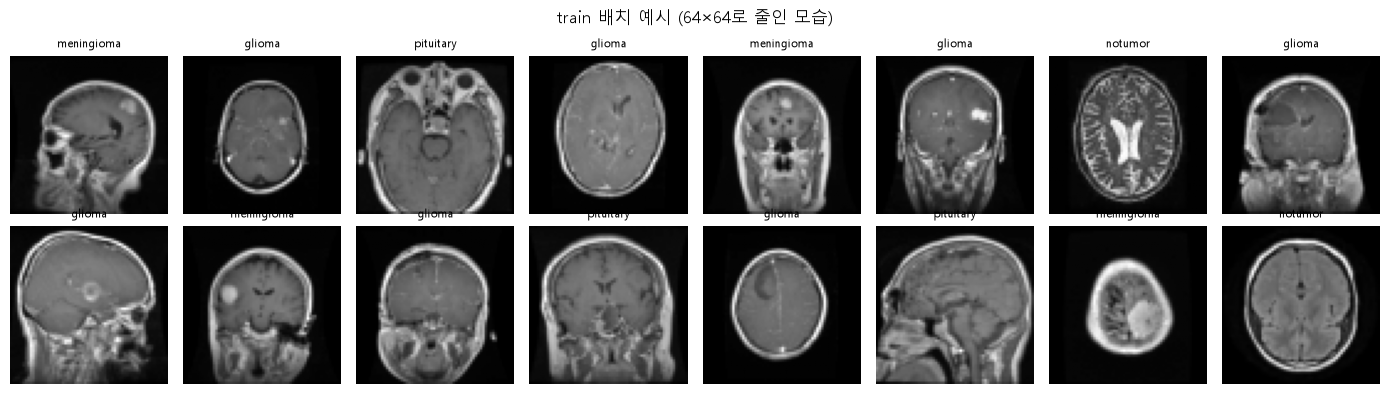

In [8]:
BATCH = 64
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=256,   shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=256,   shuffle=False, num_workers=0)

xb, yb = next(iter(train_loader))
print("배치 모양:", tuple(xb.shape), "← N×C×H×W  |  정답 모양:", tuple(yb.shape))
print(f"1 epoch = {len(train_loader)} iterations (train {len(train_ds):,}장 ÷ {BATCH})")

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, lab in zip(axes.ravel(), xb, yb):
    ax.imshow(img[0] * STD + MEAN, cmap="gray"); ax.set_title(CLASSES[lab], fontsize=8); ax.axis("off")
plt.suptitle("train 배치 예시 (64×64로 줄인 모습)"); plt.tight_layout(); plt.show()

# 정답모양이 (64,)인데, (64,1,64,64)에서 첫번째 64가 64개의 이미지를 의미하는거처럼, (64,)도 64개의 가장 확률이 높은 레이블을 포함하는것으로 이해하면 됨. 
# 64*64만으로 봐도 클래스 별 병변의 구분이 어느정도 보이는 편이며, 미세한 차이를 보기 위해서는 128, 224, 256 등으로 해상도를 키워야함. 
# 단, 원본데이터보다 해상도를 키워도 새로운 정보가 보이지 않아서 의미가 없으며, 사전학습 모델 표준은 224*224로 되어있음.
# 현재 사용하는 MLP는 해상도를 올리면 가중치가 폭발하기 때문에 해상도를 올리는 실험은 CNN부터 하는것이 적합함 

## 5. 모델 정의: MLP (다층 퍼셉트론)

이미지를 **한 줄로 쭉 펼쳐서**(64×64 → 4,096개 숫자) 일반 신경망에 넣어요.  
정형 데이터에 신경망을 쓰는 것과 똑같은 구조예요 — 픽셀 4,096개가 변수 4,096개인 셈이죠.

```
입력 1×64×64 → Flatten(4096) → Linear(512) → ReLU → Dropout
             → Linear(128) → ReLU → Linear(4) → 클래스별 점수(logit)
```

- **Linear**: `y = Wx + b` (회귀식과 같아요) - 변수 4096개를 가지고 회귀식 512개를 동시에 계산함 
- 4096개의 feature -> 512개의 feature로 축소 -> 128개의 feature로 축소 (Ex. 체중, 키를 변수로 썻다가 BMI 하나만 쓰는 느낌으로 축소함.)
- 전체 4096개의 feature 정보를 512개의 feature 정보로 요약하는것으로 PCA와 비슷한 느낌임. 다만 학습하면서 종양분류에 도움되는 방향으로 가중치가 조정되어 분류에 필요한 정보 위주로 남김 
- 맨 마지막이 linear(4) 인 이유는 클래스의 개수와 맞추어야 하기 때문임
- 반드시 줄이기만 하는 형태는 아니며 늘려가는 형태도 있음 
- **ReLU**: 양수는 그대로, 음수는 0으로 — 비선형성을 줘서 복잡한 패턴을 표현하게 함
- Activation 함수를 사용하지 않는다면 Linear 층을 쌓는 형태가 되어서 그냥 계속 Linear가 됨... (ax+b의 형태로만 나오게됨). 
- Linear 만 사용한다면 직선 그래프가 나오겠지만 중간에 ReLU를 섞어줘야 꺾은선이 나옴 (직선으로는 불가능한 모양). 이를 여러번 반복하면 꺽인선이 이어지면서 곡선처럼 나오게 됨
- 이렇게 비선형으로 만드는 이유는 우리가 풀어야 하는 문제가 비선형이기 때문에... (ex. 픽셀이 밝을수록 종양일 확률이 오름과 같은 선형적인 문제가 아님)
- **Dropout**: 학습 중 일부 뉴런을 랜덤으로 꺼서 과적합 방지. 일부 뉴런의 출력을 0으로 끄고 배치마다 꺼지는 뉴런이 다름. 특정 뉴런 몇개에만 의존하는 것을 막기 위함 
- 마지막 출력 4개는 아직 확률이 아닌 **점수(logit)** — softmax를 거치면 확률이 돼요

⚠️ **MLP의 한계**: 펼치는 순간 "어떤 픽셀이 어떤 픽셀 옆에 있는지" 정보가 사라져요. 이걸 해결한 게 다음 노트북의 **CNN**이에요.

In [9]:
class MLP(nn.Module):
    def __init__(self, in_dim=IMG_SIZE * IMG_SIZE, n_classes=len(CLASSES)):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_dim, 512), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(512, 128),    nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, n_classes),
        )
    def forward(self, x):        # 순전파: 입력 → 출력 계산 규칙
        return self.net(x)

model = MLP().to(DEVICE)
print(model)
n_params = sum(p.numel() for p in model.parameters())
print(f"\n학습할 파라미터 수: {n_params:,}개  ← 대부분 첫 Linear(4096×512)에 있어요")

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=512, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.3, inplace=False)
    (7): Linear(in_features=128, out_features=4, bias=True)
  )
)

학습할 파라미터 수: 2,163,844개  ← 대부분 첫 Linear(4096×512)에 있어요


## 6. 손실 함수 · 옵티마이저 · 학습/평가 함수

- **손실 함수 `CrossEntropyLoss`**: 다중 분류용. 정답 클래스의 확률이 낮을수록 벌점이 커요 (로지스틱 회귀의 log loss를 다중 클래스로 확장한 것)
- **옵티마이저 `Adam`**: 기울기를 보고 가중치를 얼마나 움직일지 정하는 규칙. `lr`(학습률) = 한 번에 움직이는 보폭

**학습 한 스텝의 5단계** — 이게 `fit()` 안에서 일어나던 일이에요:
```
1. optimizer.zero_grad()   이전 기울기 지우기
2. out = model(x)          순전파: 예측
3. loss = criterion(out,y) 손실 계산
4. loss.backward()         역전파: 각 가중치의 기울기 계산
5. optimizer.step()        가중치 갱신
```

- 사용하는 지표
1. 분류: CrossEntropy | 정확도, F1, AUROC 
2. 검출: 박스위치손실 + 분류손실 | mAP (예측박스가 정답박스와 맞는지, 박스 안의 라벨이 맞는지 판단)
3. 분할: Dice Loss | Dice, IoU (정답 영역과 예측 영역이 얼마나 겹치는지)

In [10]:
from sklearn.metrics import f1_score

criterion = nn.CrossEntropyLoss() # 정답클래스의 확률이 1에 가까우면 벌점이 0에 가깝고, 낮을수록 벌점이 커짐
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3) # 옵티마이저: 

def train_one_epoch(model, loader):
    model.train()                                # 학습 모드 (Dropout 켜짐)
    total_loss, correct, n = 0.0, 0, 0           
    for x, y in loader:                          # 배치 68개를 하나씩 꺼냄
        x, y = x.to(DEVICE), y.to(DEVICE)        # GPU로 옮기기
        optimizer.zero_grad()                    # 1. 이전 배치의 기울기 지우기 
        out = model(x)                           # 2. 예측 (64*4 점수)
        loss = criterion(out, y)                 # 3. 벌점 계산
        loss.backward()                          # 4. 가중치별 기울기 계산
        optimizer.step()                         # 5. 가중치 수정 
        total_loss += loss.item() * len(y)
        correct += (out.argmax(1) == y).sum().item(); n += len(y)
    return total_loss / n, correct / n

# 평가에서는 가중치를 고치지 않음 
@torch.no_grad()                                 # 평가 땐 기울기 계산 불필요 → 빠르고 메모리 절약
def evaluate(model, loader):
    model.eval()                                 # 평가 모드 (Dropout 꺼짐)
    total_loss, probs, ys = 0.0, [], []
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x)                           # 예측 
        total_loss += criterion(out, y).item() * len(y)
        probs.append(torch.softmax(out, 1).cpu()); ys.append(y.cpu())  # 점수 -> 확률
    probs, ys = torch.cat(probs).numpy(), torch.cat(ys).numpy()        # 확률 가장 큰 클래스 = 예측 
    pred = probs.argmax(1)
    return {"loss": total_loss / len(ys), "acc": (pred == ys).mean(),
            "macro_f1": f1_score(ys, pred, average="macro"), "probs": probs, "y": ys}

## 7. 학습 실행

30 epoch 돌리면서 매 epoch마다 validation 성능을 확인하고, **validation 손실이 가장 낮았던 시점의 모델을 저장**해요.  
(30 epoch가 끝났을 때의 모델이 아니라 *가장 좋았던 순간*을 남기는 것 — 과적합되기 전 시점)

In [11]:
EPOCHS = 30
CKPT = OUT / "p1_02_mlp_best.pt"
history, best_val = [], float("inf")

t0 = time.time()
for ep in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model, train_loader) # validation loss가 가장 낮을때 best 모델로 저장 
    v = evaluate(model, val_loader)
    history.append({"epoch": ep, "train_loss": tr_loss, "val_loss": v["loss"],
                    "train_acc": tr_acc, "val_acc": v["acc"], "val_macro_f1": v["macro_f1"]})
    flag = ""
    if v["loss"] < best_val:
        best_val = v["loss"]; torch.save(model.state_dict(), CKPT); flag = "  ← best 저장"
    print(f"[{ep:02d}] train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
          f"val loss {v['loss']:.3f} acc {v['acc']:.3f} macroF1 {v['macro_f1']:.3f}{flag}")
print(f"\n학습 시간: {time.time() - t0:.0f}초")
hist = pd.DataFrame(history)
# 최종 best 모델은 7 에포크 
# accuracy는 가장 높은 점수의 클래스가 맞았는지만 봄 (ex. 51%로 맞춰도 맞춘건 맞춘거임)
# loss는 확신의 정도까지 같이 봄 (ex. 99% 확신했는데 틀린경우 아주 큰 벌점이 옴)
# 학습이 길어지면 모델이 점점 과하게 확신하게 되어 맞추는 개수가 늘기는 하는데, 틀릴때 높은 확률의 확신을 가지고 틀리게 됨 
# 따라서, 확률값 자체가 중요하면 Loss, 분류 성능만 봐야하면 MacroF1 
# 초반에 Train Loss가 높고 Validation Loss 가 낮은건 학습할때는 Dropout을 켜서 핸디캡을 준 상태로 학습하고 테스트할때는 뉴런을 다 켜서 보기때문임
# train loss는 계속 감소하는데 validation loss는 7 에포크까지 감소하다가 8 에포크부터 다시 증가하기 시작하는데 이 시점에서 과적합이 있음 

[01] train loss 0.823 acc 0.682 | val loss 0.551 acc 0.803 macroF1 0.805  ← best 저장
[02] train loss 0.559 acc 0.790 | val loss 0.446 acc 0.851 macroF1 0.850  ← best 저장
[03] train loss 0.482 acc 0.820 | val loss 0.421 acc 0.830 macroF1 0.831  ← best 저장
[04] train loss 0.401 acc 0.846 | val loss 0.426 acc 0.850 macroF1 0.851
[05] train loss 0.357 acc 0.868 | val loss 0.355 acc 0.881 macroF1 0.880  ← best 저장
[06] train loss 0.306 acc 0.884 | val loss 0.352 acc 0.884 macroF1 0.883  ← best 저장
[07] train loss 0.283 acc 0.889 | val loss 0.341 acc 0.885 macroF1 0.886  ← best 저장
[08] train loss 0.242 acc 0.907 | val loss 0.383 acc 0.868 macroF1 0.863
[09] train loss 0.245 acc 0.907 | val loss 0.404 acc 0.873 macroF1 0.873
[10] train loss 0.215 acc 0.919 | val loss 0.354 acc 0.903 macroF1 0.904
[11] train loss 0.198 acc 0.927 | val loss 0.383 acc 0.878 macroF1 0.879
[12] train loss 0.187 acc 0.931 | val loss 0.381 acc 0.888 macroF1 0.888
[13] train loss 0.179 acc 0.935 | val loss 0.447 acc 0.885

## 8. 학습 곡선 ⭐

| 모양 | 의미 |
|---|---|
| train↓ val↓ 같이 내려감 | 잘 배우는 중 |
| train↓ 계속 내려가는데 val은 멈추거나 ↑ | **과적합** 시작 — 그 지점이 best |
| 둘 다 높은 채로 안 내려감 | 모델이 너무 단순하거나 학습률 문제 (과소적합) |

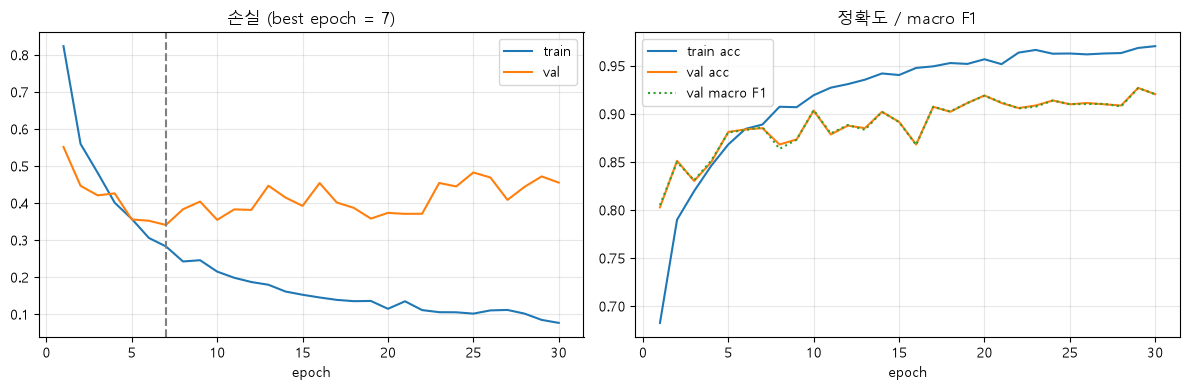

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist["epoch"], hist["train_loss"], label="train"); axes[0].plot(hist["epoch"], hist["val_loss"], label="val")
best_ep = hist.loc[hist["val_loss"].idxmin(), "epoch"]
axes[0].axvline(best_ep, ls="--", c="gray"); axes[0].set_title(f"손실 (best epoch = {best_ep})"); axes[0].legend()
axes[1].plot(hist["epoch"], hist["train_acc"], label="train acc"); axes[1].plot(hist["epoch"], hist["val_acc"], label="val acc")
axes[1].plot(hist["epoch"], hist["val_macro_f1"], label="val macro F1", ls=":")
axes[1].set_title("정확도 / macro F1"); axes[1].legend()
for ax in axes: ax.set_xlabel("epoch"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

# (오른쪽그래프) 20 에포크까지 validation 성능이 높아지고 있음 
# 20 에포크 이후는 정체구간으로 보는 것이 좋음 --> 7 에포크 이후로 loss는 증가하고 validation acc도 증가하는데, 맞추는 개수도 늘지만 틀리는건 더 확신을 가지고 틀리는 형태가 됨
# (오른쪽그래프) 정확도 기준 30 에포크 즈음에 약 5% 차이가 나는데 (train/validation) validation 정확도가 떨어지지는 않았으니 심한 과적합은 아님 
# 초록색점선: validation acc와 완전히 겹치는데, 모델이 특저 클래스만 못하는게 아니라는 의미임. 만약 하나의 클래스를 크게 놓치면 macro f1이 정확도 보다 확 낮게 나오게 됨 

## 9. Test 평가 (깨끗한 test, 딱 한 번)

best 모델을 불러와서 평가해요. 정확도 하나가 아니라 **클래스별 성능**을 봐요 (notumor test가 97장으로 적었던 것 기억!).

Accuracy          : 0.870
Balanced accuracy : 0.875   (클래스별 민감도의 평균)
Macro F1          : 0.870
Macro AUROC (OvR) : 0.973

              precision    recall  f1-score   support

      glioma      0.878     0.827     0.852       295
  meningioma      0.716     0.770     0.742       196
     notumor      0.911     0.948     0.929        97
   pituitary      0.959     0.952     0.956       294

    accuracy                          0.870       882
   macro avg      0.866     0.875     0.870       882
weighted avg      0.872     0.870     0.870       882

클래스별 AUROC (해당 클래스 vs 나머지):
  glioma      0.966
  meningioma  0.931
  notumor     0.997
  pituitary   0.997


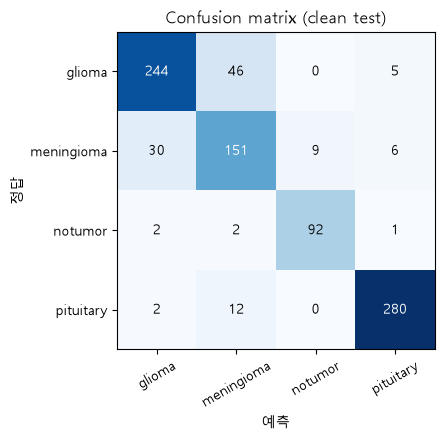

In [13]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, balanced_accuracy_score

model.load_state_dict(torch.load(CKPT, map_location=DEVICE))
r = evaluate(model, test_loader)
pred = r["probs"].argmax(1)

print(f"Accuracy          : {r['acc']:.3f}")
print(f"Balanced accuracy : {balanced_accuracy_score(r['y'], pred):.3f}   (클래스별 민감도의 평균)")
print(f"Macro F1          : {r['macro_f1']:.3f}")
print(f"Macro AUROC (OvR) : {roc_auc_score(r['y'], r['probs'], multi_class='ovr'):.3f}\n")
print(classification_report(r["y"], pred, target_names=CLASSES, digits=3))

print("클래스별 AUROC (해당 클래스 vs 나머지):")
for i, c in enumerate(CLASSES):
    print(f"  {c:<11} {roc_auc_score(r['y'] == i, r['probs'][:, i]):.3f}")

cm = confusion_matrix(r["y"], pred)
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=30); ax.set_yticks(range(len(CLASSES)), CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("예측"); ax.set_ylabel("정답"); ax.set_title("Confusion matrix (clean test)")
plt.tight_layout(); plt.show()

# validation 에서의 성능과 test 에서의 성능이 거의 동일함 -> 어느정도 일반화도 되어있다는 얘기
# 오류 대부분이 glioma, meningioma 사이에 몰려있음. precision도 0.716으로 낮은편 
# 두 클래스의 데이터를 확인해보면 두개 다 T1 조영 영상이며 방향이 섞여있고 촬영스타일 자체가 좀 비슷함
# 분류가 잘된 나머지 두개 클래스는 T2영상이거나 단면 방향이 다름 등의 차이가 있음 
# notumor와 pituitary는 종양을 거의 보지 않고 사진 스타일만으로도 거의 맞출수 있나? 라는 의문이 들수있음
# glioma와 meningioma가 어려운 이유는 이 두개의 종양은 위치와 모양에 차이가 있는데 MLP는 위치와 모양까지 보지 않기 때문임 

### 📝 메모: MLP test 결과 (clean test 882장)
- Acc 0.870 / Balanced acc 0.875 / Macro F1 0.870 / Macro AUROC 0.973 (val 0.885와 비슷 → 일반화 OK)
- 오류의 66%가 glioma ↔ meningioma 혼동 (46 + 30장), meningioma precision 0.716로 가장 낮음
- notumor·pituitary AUROC 0.997 ← EDA에서 본 촬영 방식·단면 방향 차이(지름길) 때문일 가능성 → Grad-CAM으로 확인 예정
- glioma vs meningioma는 위치·모양이 핵심인데 MLP는 위치 정보를 잃음 → CNN에서 가장 개선될 것으로 예상

## 10. 누수 실험 ⭐⭐

같은 모델로 test를 세 가지 버전으로 평가해요.
확인하는 이유: 누수를 넣은 데이터와 누수를 제외한 데이터를 넣었을 때의 성능 차이를 확인함으로써, 누수가 영향을 얼마나 미치는지를 확인하기 위함 
1. **깨끗한 test** — 위에서 본 것
2. **원본 test** (1,311장, 누수 413장 포함) — 노트북 1의 정리를 안 했다면 보고했을 점수
3. **누수된 413장만** — train에 쌍둥이가 있는 이미지들

→ 2와 1의 차이가 **"누수 때문에 부풀려진 만큼"**이에요.

In [ ]:
orig_test = full[full["split"] == "test"].reset_index(drop=True)
leak_only = orig_test[orig_test["test_leak"]].reset_index(drop=True)

rows = []
for name, d in [("① 깨끗한 test", test_df), ("② 원본 test", orig_test), ("③ 누수 이미지만", leak_only)]:
    ds = test_ds if d is test_df else BrainMRIDataset(d, MEAN, STD, desc=name)
    res = evaluate(model, DataLoader(ds, batch_size=256))
    rows.append({"평가셋": name, "장수": len(d), "accuracy": res["acc"], "macro F1": res["macro_f1"]})
leak_tbl = pd.DataFrame(rows).set_index("평가셋").round(3)
leak_tbl

# 누수로 인해서 성능이 많이 상승하지는 않았으나 이는 MLP + Dropout 이라는 구조로 인해서 발생하기도 함. 해당 구조는 이미지를 외우는 능력 자체가 약하고 7epoch 시점의 모델이라서 과적합 전의 모델이기 때문임
# 또, 누수 이미지의 구성은 notumor 295장 + meningioma 108장 + pituitary 6장 + glioma 4장으로 잘 맞추는 클래스인 notumor가 대부분이라서 해당 클래스의 성능에서 나온 걸 수 있음. 
# 다만 macro f1이 낮은건 다른 소수 클래스 (pituitary, glioma 등)의 개수가 적어 성능이 잘 흔들리기 때문일거임 

③ 누수 이미지만 이미지 로딩: 100%|██████████| 413/413 [00:00<00:00, 632.52it/s]


,장수,accuracy,macro F1
평가셋,,,
① 깨끗한 test,882,0.870,0.870
② 원본 test,1311,0.871,0.868
③ 누수 이미지만,413,0.874,0.737


In [ ]:
# 외운 모델이면 누수효과가 커질지를 확인하고 싶어짐 
# 실험: 마지막(외운) 모델 vs best 모델로 누수 효과 비교
torch.manual_seed(SEED)
model_last = MLP().to(DEVICE)
optimizer = torch.optim.Adam(model_last.parameters(), lr=1e-3)   # 새 모델용 옵티마이저로 교체
for ep in range(1, 61):                                            # 60 epoch: 더 오래 학습 = 더 외움
    tr_loss, tr_acc = train_one_epoch(model_last, train_loader)
print(f"60 epoch 후 train acc: {tr_acc:.3f}")

def acc_by_class(m, d):
    ds = test_ds if d is test_df else BrainMRIDataset(d, MEAN, STD, desc="")
    r = evaluate(m, DataLoader(ds, batch_size=256))
    return r["acc"], pd.Series(r["probs"].argmax(1) == r["y"]).groupby(d["label"].values).mean()

rows = []
for mname, m in [("best(7ep)", model), ("last(60ep)", model_last)]:
    for dname, d in [("① 깨끗한", test_df), ("② 원본", orig_test), ("③ 누수만", leak_only)]:
        acc, by_cls = acc_by_class(m, d)
        rows.append({"모델": mname, "평가셋": dname, "acc": acc, **by_cls.round(3).to_dict()})
pd.DataFrame(rows).set_index(["모델", "평가셋"]).round(3)

# 더 잘 외우게 될수록 누수 데이터를 쓰면 더 성능이 잘나오게 됨 (특히 meningioma의 성능이 가장 많이 오름)
# 기존의 30에포크를 했을때보다 60 에포크를 했을때 모델의 성능이 더 좋은데, 과적합된 모델이 오히려 성능이 더 잘나오는 상황임. 즉, val loss로 best를 고른게 정확도 면에서는 손해였음. 
# 다만 어느 부분에 초점을 맞춰서 볼건지에 따라서 평가 지표를 정하고 모델을 정하는것이 좋음 
# 60 에포크 MLP가 notumor 0.99, pituitary 1.00 으로 나왔는데, 촬영방식과 단면 방향 차이로 맞추고 있을 가능성이 높아짐 

60 epoch 후 train acc: 0.986


 이미지 로딩: 100%|██████████| 413/413 [00:00<00:00, 617.82it/s]


acc  glioma  meningioma  notumor  pituitary
모델         평가셋                                                 
best(7ep)  ① 깨끗한  0.870   0.827       0.770    0.948      0.952
           ② 원본   0.871   0.830       0.771    0.916      0.953
           ③ 누수만  0.874   1.000       0.787    0.902      1.000
last(60ep) ① 깨끗한  0.922   0.898       0.806    0.990      1.000
           ② 원본   0.935   0.900       0.846    0.980      1.000
           ③ 누수만  0.966   1.000       0.935    0.976      1.000

## ✍️ 정리 & 생각해볼 질문

1. 학습 곡선에서 과적합이 보였나? 몇 epoch쯤부터?
2. 어떤 클래스끼리 가장 많이 헷갈렸나? (confusion matrix) 노트북 1에서 본 "지름길" 관찰과 연결되는 게 있나?
3. 누수 실험에서 ②가 ①보다 얼마나 높았나? ③은? 논문에서 원본 test로 보고했다면 무슨 일이 생겼을까?
4. MLP가 이미지를 한 줄로 펼칠 때 잃어버리는 정보는 뭘까?

**메모:**
- 
